# 06 · Revisión de la validación y ataque no visto

Este notebook agrega dos revisiones de la Etapa III, sin modificar el modelo final del notebook 04:

1. **Filas repetidas con las variables del modelo.** El notebook 01 no encontró duplicados, pero los buscó con las 45 columnas originales, incluidas `IAT`, `Number` y `Weight`. Al usar solo las variables del modelo, dos flujos distintos pueden quedar idénticos. Si una fila de validación repite una de entrenamiento, el F1 de validación estaría inflado.
2. **Ataque no visto.** Desde la Etapa III los datos incluyen **DDoS MQTT** (MQTT Publish Flood, sobre el protocolo que usan los monitores médicos) y **DDoS ICMP** (ICMP flood). Aquí se compara un detector entrenado **sin** esos ataques, como el de la Presentación 2, con uno entrenado **con** ellos, evaluando ambos en la misma prueba oficial.

La segunda revisión mide un cambio distinto al de la evaluación cruzada: la red es la misma, pero cambia el tipo de ataque (*concept drift*). CIC-DDoS2019 no trae estos ataques, así que esta parte es solo dentro de IoMT.

**Datos necesarios:** los CSV de `DESCARGA_DATOS.txt`, incluida la sección 6. Con `NIDS_ATAQUES_NUEVOS=0` se ejecuta solo la sección 2.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ.resolve()))

from src.evaluate import configurar_graficos
configurar_graficos()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight

from src.data_loader import (
    CLASES, CLASES_COMPARTIDAS, cargar_particion, columnas_caracteristicas, limpiar,
)
from src.features import VARIABLES_SOSPECHOSAS, preprocesador, seleccionar_variables
from src.evaluate import guardar_tabla, metricas_binarias

SEMILLA = 42

## 1. Partición original

Se reconstruye la partición de los notebooks 01 y 02 directamente desde los CSV: entrenamiento 80 %, validación 20 % y la prueba oficial como captura separada. Así este notebook no depende de `data/processed/`, que el script `src/aplicar_split_80_20.py` puede haber sobrescrito con otra partición.

In [2]:
entrenamiento_completo, _ = limpiar(cargar_particion("train"), eliminar_filas=True)
prueba, _ = limpiar(cargar_particion("test"), eliminar_filas=False)

entrenamiento, validacion = train_test_split(
    entrenamiento_completo,
    test_size=0.20,
    stratify=entrenamiento_completo["clase"],
    random_state=SEMILLA,
)

columnas = columnas_caracteristicas(entrenamiento_completo)
variables, _ = seleccionar_variables(entrenamiento[columnas], 0.98, VARIABLES_SOSPECHOSAS)

print("Variables del modelo:", len(variables))
print(f"Entrenamiento: {len(entrenamiento):,} | Validación: {len(validacion):,} | Prueba oficial: {len(prueba):,}")

Variables del modelo: 35
Entrenamiento: 660,724 | Validación: 165,181 | Prueba oficial: 624,074


## 2. ¿Hay filas repetidas con las variables del modelo?

Se cuenta cuántas filas de validación y de la prueba oficial tienen **exactamente** el mismo vector de 34 variables que alguna fila de entrenamiento. Cada fila se resume con un hash para comparar rápido.

In [3]:
def repetidas_en(referencia, datos, cols):
    """Máscara de las filas de `datos` cuyo vector de variables aparece igual en `referencia`."""
    claves_referencia = pd.util.hash_pandas_object(referencia[cols], index=False)
    claves_datos = pd.util.hash_pandas_object(datos[cols], index=False)
    return claves_datos.isin(claves_referencia).to_numpy()


duplicados_entrenamiento = entrenamiento[variables].duplicated()
repetidas_val = repetidas_en(entrenamiento, validacion, variables)
repetidas_prueba = repetidas_en(entrenamiento, prueba, variables)

filas = []
for conjunto, datos, mascara in [
    ("Entrenamiento (repetidas dentro del mismo conjunto)", entrenamiento, duplicados_entrenamiento.to_numpy()),
    ("Validación (iguales a una fila de entrenamiento)", validacion, repetidas_val),
    ("Prueba oficial (iguales a una fila de entrenamiento)", prueba, repetidas_prueba),
]:
    fila = {"Conjunto": conjunto, "Filas": len(datos), "Repetidas": int(mascara.sum()),
            "% repetidas": 100 * mascara.mean()}
    for clase, nombre in CLASES.items():
        de_la_clase = datos["clase"].to_numpy() == clase
        fila[f"% repetidas {nombre}"] = 100 * mascara[de_la_clase].mean()
    filas.append(fila)

revision_duplicados = pd.DataFrame(filas).set_index("Conjunto")
display(revision_duplicados.round(2))
guardar_tabla(revision_duplicados, "revision_duplicados_variables_modelo")

,Filas,Repetidas,% repetidas,% repetidas Benigno,% repetidas DDoS SYN,% repetidas DDoS UDP,% repetidas DDoS MQTT,% repetidas DDoS ICMP
Conjunto,,,,,,,,
Entrenamiento (repetidas dentro del mismo conjunto),660724,160352,24.27,0.0,27.67,0.0,0.0,72.64
Validación (iguales a una fila de entrenamiento),165181,44360,26.86,0.0,30.98,0.0,0.0,80.01
Prueba oficial (iguales a una fila de entrenamiento),624074,74363,11.92,0.0,8.07,0.0,0.0,30.22


PosixPath('/Users/makise/Documents/GitHub/Data-Science/Sin título/deliverables/resultados/revision_duplicados_variables_modelo.csv')

### Modelo de referencia

Se reentrena el **LightGBM binario** del notebook 04 con los hiperparámetros elegidos en la Presentación 2 (tabla `busqueda_hiperparametros.csv`) y los mismos pesos por clase, ahora con todas las clases disponibles. Con `NIDS_ATAQUES_NUEVOS=0` debería reproducir el resultado de la Presentación 2 en la prueba oficial (F1 macro ≈ 0,9967, 0 falsas alarmas).

Luego se compara la validación completa con la validación **sin** las filas repetidas: si el F1 casi no cambia, las repeticiones no explican las métricas altas.

In [4]:
# Hiperparámetros elegidos en el notebook 04 (deliverables/resultados/busqueda_hiperparametros.csv)
PARAMETROS_LGBM_BINARIA = {
    "colsample_bytree": 0.749816047538945,
    "learning_rate": 0.262516606324193,
    "min_child_samples": 81,
    "n_estimators": 288,
    "num_leaves": 35,
    "subsample": 0.6624074561769746,
    "subsample_freq": 1,
}
PARAMETROS_LGBM_MULTICLASE = {
    "colsample_bytree": 0.6092249700165663,
    "learning_rate": 0.08283481117034153,
    "min_child_samples": 51,
    "n_estimators": 575,
    "num_leaves": 74,
    "subsample": 0.7465447373174767,
    "subsample_freq": 1,
}


def entrenar_lgbm(datos, objetivo, parametros):
    modelo = Pipeline([
        ("prep", preprocesador()),
        ("modelo", LGBMClassifier(n_jobs=-1, random_state=SEMILLA, verbose=-1, **parametros)),
    ])
    modelo.fit(
        datos[variables], datos[objetivo],
        modelo__sample_weight=compute_sample_weight("balanced", datos[objetivo]),
    )
    return modelo


modelo_binario = entrenar_lgbm(entrenamiento, "etiqueta", PARAMETROS_LGBM_BINARIA)

def evaluar_binario(modelo, datos):
    return metricas_binarias(datos["etiqueta"], modelo.predict(datos[variables]), clase_real=datos["clase"])

comparacion_validacion = pd.DataFrame({
    "Validación completa": evaluar_binario(modelo_binario, validacion),
    "Validación sin filas repetidas": evaluar_binario(modelo_binario, validacion[~repetidas_val]),
    "Prueba oficial completa": evaluar_binario(modelo_binario, prueba),
    "Prueba oficial sin filas repetidas": evaluar_binario(modelo_binario, prueba[~repetidas_prueba]),
}).T
comparacion_validacion[["Falsas alarmas", "Ataques no detectados"]] = (
    comparacion_validacion[["Falsas alarmas", "Ataques no detectados"]].astype(int)
)

columnas_clave = (["F1 macro"] + [f"Recall {n.split()[-1]}" for c, n in CLASES.items() if c > 0]
                  + ["Tasa falsos positivos", "Falsas alarmas", "Ataques no detectados"])
display(comparacion_validacion[columnas_clave].round(5))
guardar_tabla(comparacion_validacion, "validacion_sin_repetidas")

,F1 macro,Recall SYN,Recall UDP,Recall MQTT,Recall ICMP,Tasa falsos positivos,Falsas alarmas,Ataques no detectados
Validación completa,0.99996,0.99997,0.99998,1.00000,0.99995,0.00003,1,4
Validación sin filas repetidas,0.99995,0.99996,0.99998,1.00000,0.99975,0.00003,1,4
Prueba oficial completa,0.99124,0.99840,0.99987,0.89116,0.99980,0.00000,0,1258
Prueba oficial sin filas repetidas,0.99116,0.99826,0.99987,0.89116,0.99971,0.00000,0,1258


PosixPath('/Users/makise/Documents/GitHub/Data-Science/Sin título/deliverables/resultados/validacion_sin_repetidas.csv')

In [5]:
f1 = comparacion_validacion["F1 macro"]
print(f"{revision_duplicados['% repetidas'].iloc[1]:.1f} % de la validación repite una fila de entrenamiento.")
print(f"F1 macro en validación: {f1['Validación completa']:.5f} con todas las filas "
      f"y {f1['Validación sin filas repetidas']:.5f} sin las repetidas "
      f"(diferencia {f1['Validación completa'] - f1['Validación sin filas repetidas']:+.5f}).")
print(f"F1 macro en la prueba oficial: {f1['Prueba oficial completa']:.5f} con todas las filas "
      f"y {f1['Prueba oficial sin filas repetidas']:.5f} sin las repetidas.")

26.9 % de la validación repite una fila de entrenamiento.
F1 macro en validación: 0.99996 con todas las filas y 0.99995 sin las repetidas (diferencia +0.00001).
F1 macro en la prueba oficial: 0.99124 con todas las filas y 0.99116 sin las repetidas.


**Cómo leer esta sección.**

- Si el F1 sin filas repetidas es prácticamente igual al F1 completo, las repeticiones no inflan el resultado: el modelo también acierta en flujos que nunca vio con esos valores exactos.
- Si el F1 baja de forma visible, parte del 0,99995 de validación se explica por filas repetidas, y conviene deduplicar con las 34 variables antes de partir los datos (notebook 02) y reentrenar.
- En cualquiera de los dos casos, la prueba oficial sigue siendo la medida principal, porque es una captura separada.

## 3. Ataque no visto

### 3.1 Sin los ataques nuevos en entrenamiento: ¿los reconoce igual?

Se entrena el mismo LightGBM binario solo con benigno, SYN y UDP, como el detector de la Presentación 2, y se evalúa en la prueba oficial completa. Como los flujos de MQTT e ICMP son todos ataque, la métrica clave es la **tasa de detección** (recall): qué proporción se marca como DDoS. SYN y UDP sirven de referencia.

In [6]:
CLASES_NUEVAS = [c for c in CLASES if c not in CLASES_COMPARTIDAS]
HAY_ATAQUES_NUEVOS = bool(CLASES_NUEVAS)
if not HAY_ATAQUES_NUEVOS:
    print("NIDS_ATAQUES_NUEVOS=0: se omite la sección 3.")


def fila_deteccion(modelo, datos, clase):
    proba = modelo.predict_proba(datos[variables])[:, 1]
    detectado = proba >= 0.5
    return {
        "Ataque": CLASES[clase],
        "¿Visto en entrenamiento?": "Sí" if clase in CLASES_COMPARTIDAS else "No",
        "Flujos de prueba": len(datos),
        "Tasa de detección": detectado.mean(),
        "No detectados": int((~detectado).sum()),
        "Prob. media de ataque": proba.mean(),
    }


if HAY_ATAQUES_NUEVOS:
    entrenamiento_sin_nuevos = entrenamiento[entrenamiento["clase"].isin(CLASES_COMPARTIDAS)]
    modelo_sin_nuevos = entrenar_lgbm(entrenamiento_sin_nuevos, "etiqueta", PARAMETROS_LGBM_BINARIA)

    deteccion_sin_reentrenar = pd.DataFrame([
        fila_deteccion(modelo_sin_nuevos, prueba[prueba["clase"] == clase], clase)
        for clase in CLASES if clase > 0
    ]).set_index("Ataque")
    display(deteccion_sin_reentrenar.round(4))
    guardar_tabla(deteccion_sin_reentrenar, "ataque_no_visto_sin_reentrenar")

,¿Visto en entrenamiento?,Flujos de prueba,Tasa de detección,No detectados,Prob. media de ataque
Ataque,,,,,
DDoS SYN,Sí,172397,0.9979,361,0.9979
DDoS UDP,Sí,205654,0.9998,49,0.9998
DDoS MQTT,No,8416,0.0031,8390,0.0042
DDoS ICMP,No,200000,0.9977,451,0.9904


### 3.2 ¿A qué clase conocida se parece el ataque nuevo?

Un LightGBM **multiclase** entrenado solo con benigno, SYN y UDP está obligado a elegir una de esas tres clases. Ver cuál elige para los ataques nuevos ayuda a explicar los resultados: si el MQTT flood se clasifica como benigno, el detector lo confunde con el tráfico normal de los dispositivos.

Clase asignada,Benigno,DDoS SYN,DDoS UDP
Ataque nuevo,,,
DDoS MQTT,0.9960,0.0039,0.0001
DDoS ICMP,0.9951,0.0016,0.0033


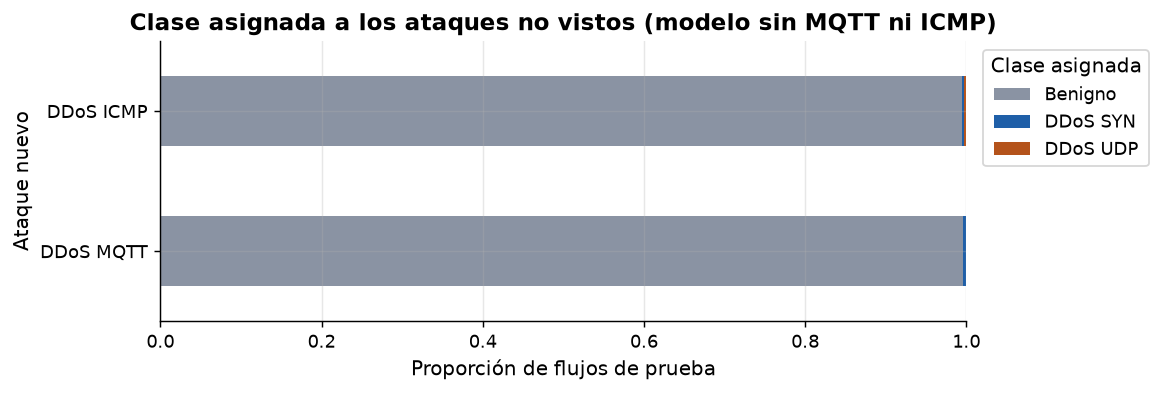

In [7]:
if HAY_ATAQUES_NUEVOS:
    modelo_multiclase_sin_nuevos = entrenar_lgbm(
        entrenamiento_sin_nuevos, "clase", PARAMETROS_LGBM_MULTICLASE
    )
    conocidas = [CLASES[c] for c in CLASES_COMPARTIDAS]

    parecido = pd.DataFrame({
        CLASES[clase]: pd.Series(
            modelo_multiclase_sin_nuevos.predict(prueba.loc[prueba["clase"] == clase, variables])
        ).map(CLASES).value_counts(normalize=True)
        for clase in CLASES_NUEVAS
    }).T.reindex(columns=conocidas).fillna(0)
    parecido.index.name = "Ataque nuevo"
    parecido.columns.name = "Clase asignada"

    display(parecido.round(4))
    guardar_tabla(parecido, "ataque_no_visto_clase_asignada")

    ax = parecido.plot.barh(stacked=True, figsize=(8, 2.8), color=["#8A93A3", "#1F5FA8", "#B4531B"])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Proporción de flujos de prueba")
    ax.set_title("Clase asignada a los ataques no vistos (modelo sin MQTT ni ICMP)")
    ax.legend(title="Clase asignada", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.show()

### 3.3 Con los ataques nuevos en entrenamiento

Se compara el detector sin MQTT ni ICMP con el de la sección 2, entrenado con todas las clases, en la misma prueba oficial. Interesa ver dos cosas:

- cuánto sube la detección de los ataques nuevos, y
- si agregar ataques empeora lo que ya funcionaba (falsas alarmas sobre el benigno, recall de SYN y UDP).

,F1 macro,Tasa falsos positivos,Falsas alarmas,Ataques no detectados,Recall DDoS SYN,Recall DDoS UDP,Recall DDoS MQTT,Recall DDoS ICMP
Sin MQTT ni ICMP en entrenamiento,0.9413,0.0,0,9251,0.9979,0.9998,0.0031,0.9977
Con MQTT e ICMP en entrenamiento,0.9912,0.0,0,1258,0.9984,0.9999,0.8912,0.9998


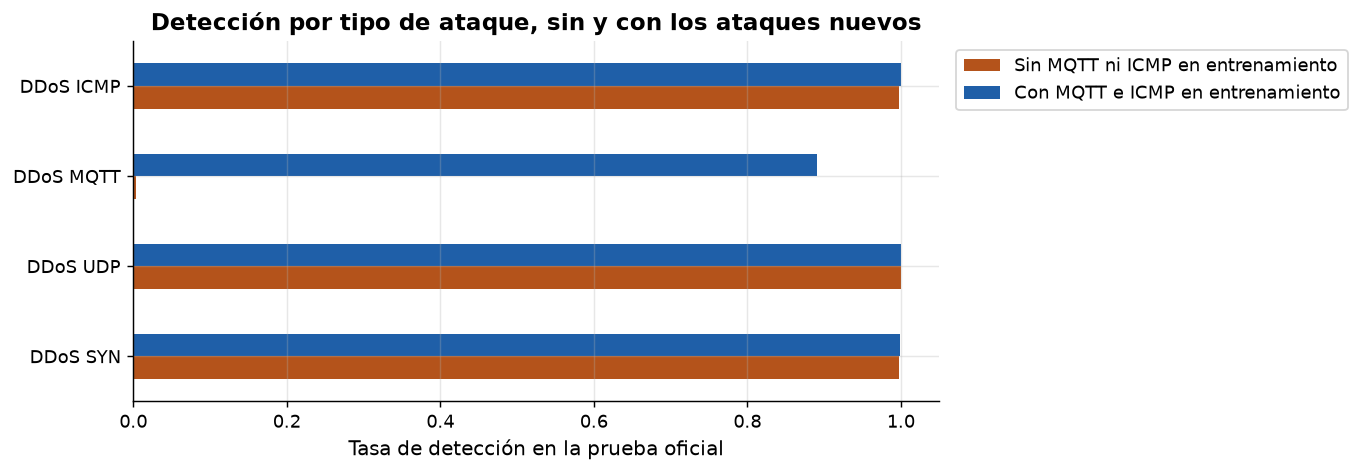

In [8]:
def resumen_binario(modelo, datos):
    y = datos["etiqueta"].to_numpy()
    clase = datos["clase"].to_numpy()
    pred = modelo.predict(datos[variables])
    fila = {
        "F1 macro": f1_score(y, pred, average="macro"),
        "Tasa falsos positivos": (pred[y == 0] == 1).mean(),
        "Falsas alarmas": int(((pred == 1) & (y == 0)).sum()),
        "Ataques no detectados": int(((pred == 0) & (y == 1)).sum()),
    }
    for c in CLASES:
        if c > 0:
            fila[f"Recall {CLASES[c]}"] = (pred[clase == c] == 1).mean()
    return fila


if HAY_ATAQUES_NUEVOS:
    reentrenamiento = pd.DataFrame({
        "Sin MQTT ni ICMP en entrenamiento": resumen_binario(modelo_sin_nuevos, prueba),
        "Con MQTT e ICMP en entrenamiento": resumen_binario(modelo_binario, prueba),
    }).T
    reentrenamiento[["Falsas alarmas", "Ataques no detectados"]] = (
        reentrenamiento[["Falsas alarmas", "Ataques no detectados"]].astype(int)
    )
    display(reentrenamiento.round(4))
    guardar_tabla(reentrenamiento, "ataque_no_visto_reentrenamiento")

    recalls = reentrenamiento.filter(like="Recall").T
    recalls.index = recalls.index.str.removeprefix("Recall ")
    ax = recalls.plot.barh(figsize=(8, 3.6), color=["#B4531B", "#1F5FA8"])
    ax.set_xlim(0, 1.05)
    ax.set_xlabel("Tasa de detección en la prueba oficial")
    ax.set_title("Detección por tipo de ataque, sin y con los ataques nuevos")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.show()

In [9]:
if HAY_ATAQUES_NUEVOS:
    for clase in CLASES_NUEVAS:
        nombre = CLASES[clase]
        antes = reentrenamiento.iloc[0][f"Recall {nombre}"]
        despues = reentrenamiento.iloc[1][f"Recall {nombre}"]
        print(f"{nombre}: el detector sin este ataque marca como DDoS el {100 * antes:.1f} % de sus flujos; "
              f"al incluirlo en el entrenamiento, el {100 * despues:.1f} %.")
    fa = reentrenamiento["Falsas alarmas"]
    print(f"Falsas alarmas sobre el benigno: {fa.iloc[0]} sin y {fa.iloc[1]} con los ataques nuevos.")

DDoS MQTT: el detector sin este ataque marca como DDoS el 0.3 % de sus flujos; al incluirlo en el entrenamiento, el 89.1 %.
DDoS ICMP: el detector sin este ataque marca como DDoS el 99.8 % de sus flujos; al incluirlo en el entrenamiento, el 100.0 %.
Falsas alarmas sobre el benigno: 0 sin y 0 con los ataques nuevos.


## 4. Cómo interpretar el ataque no visto

- **Si la tasa de detección sin los ataques nuevos es baja**, el detector solo protege contra los ataques que vio: aprendió las firmas de SYN y UDP (tamaño y tasa de paquetes), no un concepto general de «ataque». Es el mismo fenómeno del notebook 03 (el modelo entrenado sin UDP no detectó ningún UDP flood) y complementa la evaluación cruzada: el detector falla tanto al cambiar de red como al cambiar de ataque.
- **Si la tasa es alta**, el ataque nuevo comparte rasgos con los que ya conoce (por ejemplo, alta tasa de paquetes) y el detector generaliza dentro de la familia de floods volumétricos. La sección 3.2 muestra con qué clase lo confunde.
- **Con los ataques en entrenamiento**, se espera que su detección suba. Lo importante para el hospital es que no aumenten las falsas alarmas ni baje el recall de SYN y UDP.
- **Límite:** estos ataques no existen en CIC-DDoS2019, así que no se pueden incluir en la evaluación cruzada entre redes.